# Video search MVP: reference image (+ natural language) -> clips
**Stage 1 (once per video):** decode at `SAMPLE_FPS`, DFN CLIP embeddings per frame, InsightFace face detection + embeddings per frame, cached to disk.
**Stage 2 (every query), `search(image, text)`:**
- **image only:** a face detector checks the image. Prominent face -> *face lane* (ArcFace-style match). No prominent face -> *image lane* (DFN image-to-image similarity).
- **image + text** (e.g. `"this actor in a red shirt"`): identity comes from the image, the attribute phrase (`a red shirt`) is checked on the **body region under the matched face** with DFN; a frame must pass **both**.
- **text only:** DFN text search over frames (for a named person this is a long shot: attach a photo for real identity matching).
Matching frames are merged into **clips** (cut with ffmpeg, optionally stitched).
InsightFace's pretrained models are **non-commercial research use only**. Enable **GPU** and **Internet**.

In [1]:
import subprocess, sys, shutil
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "insightface", "open_clip_torch"])
subprocess.run([sys.executable, "-m", "pip", "uninstall", "-y", "-q", "onnxruntime"])
subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-U", "onnxruntime-gpu"])   # falls back to CPU automatically if this cannot load
if not shutil.which("ffmpeg"): subprocess.run("apt-get update -qq && apt-get install -y -qq ffmpeg", shell=True)
FFMPEG = shutil.which("ffmpeg"); assert FFMPEG

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.2/1.2 MB 19.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.5/1.5 MB 50.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 44.8/44.8 kB 3.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 23.8/23.8 MB 69.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 255.6/255.6 MB 7.6 MB/s eta 0:00:00


In [2]:
import os, re, time, math, gc, subprocess, numpy as np, cv2, torch      # torch first: loads the CUDA libs onnxruntime needs
import matplotlib.pyplot as plt
import onnxruntime as ort

D = "/kaggle/input/datasets/seewhee1130/video-dataset-krishna-2/Cardboard_dataset/"
VIDEO_PATH = D + "trump.mp4"
REF_IMAGE  = D + "trump.jpeg"   # a photo (face portrait, or any object/scene image); None for text-only
QUERY_TEXT = ""            # "", "wearing a red tie", "this actor in a red shirt", "lion"...
LANE       = "auto"        # "auto" | "face" | "image"  (force a lane if the router guesses wrong)
SAMPLE_FPS, MAX_WIDTH = 2, 1280
FACE_DET_SIZE, FACE_DET_THRESH = (960, 960), 0.5
FACE_MIN_FRAC, FACE_MIN_SCORE = 0.03, 0.6   # router: reference counts as a "face photo" if its largest face covers >= 3% of the image
FACE_THRESH = 0.35         # cosine above which a video face counts as the same person (tune on your labels; there is no universal value)
Z_IMAGE, Z_TEXT = 2.0, 2.5 # image/text lanes: a frame matches if its score is this many std-devs above the video's mean score (heuristic)
ATTR_MARGIN = 0.0          # non-color attributes: cos(attr prompt) - cos("a photo of a person") must exceed this
MERGE_GAP_SEC, PAD_SEC, MIN_CLIP_SEC = 1.5, 0.5, 0.0
STITCH, N_SHOW = True, 6
LABELS = []                # optional [(start_s, end_s), ...] of true appearances -> frame-level precision/recall of the returned clips
OUT_DIR = "/kaggle/working"; CLIP_BACKEND = None   # CLIP_BACKEND: inject another encoder (testing); None = DFN
print("onnxruntime providers:", ort.get_available_providers(), "| torch cuda:", torch.cuda.is_available())

onnxruntime providers: ['TensorrtExecutionProvider', 'CUDAExecutionProvider', 'CPUExecutionProvider'] | torch cuda: True


In [3]:
# ---- models ----
class DFNBackend:
    HUB = "hf-hub:apple/DFN2B-CLIP-ViT-L-14"
    def __init__(self):
        import open_clip
        self.m, _, self.pre = open_clip.create_model_and_transforms(self.HUB, precision="fp16", device="cuda"); self.m.eval()
        self.tok = open_clip.get_tokenizer(self.HUB)
    def encode_images(self, imgs, bs=32):
        from PIL import Image
        out = []
        with torch.inference_mode():
            for i in range(0, len(imgs), bs):
                px = torch.stack([self.pre(Image.fromarray(x)) for x in imgs[i:i + bs]]).half().cuda()
                e = self.m.encode_image(px).float(); out.append((e / e.norm(dim=-1, keepdim=True)).cpu().numpy())
        return np.concatenate(out) if out else np.zeros((0, 768), np.float32)
    def encode_text(self, texts):
        with torch.inference_mode():
            e = self.m.encode_text(self.tok(list(texts)).cuda()).float(); return (e / e.norm(dim=-1, keepdim=True)).cpu().numpy()

class FaceEngine:
    def __init__(self):
        from insightface.app import FaceAnalysis
        self.gpu = "CUDAExecutionProvider" in ort.get_available_providers()
        self.app = FaceAnalysis(name="buffalo_l", allowed_modules=["detection", "recognition"],
                                providers=["CUDAExecutionProvider", "CPUExecutionProvider"] if self.gpu else ["CPUExecutionProvider"])
        self.ctx, self._size = (0 if self.gpu else -1), None
        self.use(FACE_DET_SIZE)
    def use(self, size):
        if self._size != size: self.app.prepare(ctx_id=self.ctx, det_thresh=FACE_DET_THRESH, det_size=size); self._size = size
    def detect(self, rgb, size=None):
        self.use(size or FACE_DET_SIZE)
        return [dict(box=np.array(f.bbox, float), score=float(f.det_score), emb=f.normed_embedding.astype(np.float32))
                for f in self.app.get(cv2.cvtColor(np.ascontiguousarray(rgb), cv2.COLOR_RGB2BGR))]
    def detect_reference(self, rgb):   # close-up portraits can fail at big detector sizes (they get upscaled), so try a ladder
        for size in [(640, 640), (320, 320), (480, 480), FACE_DET_SIZE]:
            fs = self.detect(rgb, size)
            if fs: return fs
        return []

clip = DFNBackend() if CLIP_BACKEND is None else CLIP_BACKEND()
faces = FaceEngine(); print("face runtime:", "GPU" if faces.gpu else "CPU (slower)")

open_clip_config.json:   0%|          | 0.00/634 [00:00<?, ?B/s]

open_clip_pytorch_model.bin: reconstructing file:   0%|          |  0.00B / 1.71GB            

open_clip_pytorch_model.bin: downloading bytes:           |  0.00B            

download_path: /root/.insightface/models/buffalo_l


100%|██████████| 281857/281857 [00:02<00:00, 101520.17KB/s]


Failed to load libcublasLt.so.13: libcublasLt.so.13: cannot open shared object file: No such file or directory
Failed to load libcublas.so.13: libcublas.so.13: cannot open shared object file: No such file or directory
Failed to load libcudart.so.13: libcudart.so.13: cannot open shared object file: No such file or directory
Please follow https://onnxruntime.ai/docs/install/#cuda-and-cudnn to install CUDA.


2026-10-14 11:29:46.066030346 [E:onnxruntime:Default, provider_bridge_ort.cc:2458 operator()] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:2043 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library /usr/local/lib/python3.13/dist-packages/onnxruntime/capi/libonnxruntime_providers_cuda.so with error: libcublasLt.so.13: cannot open shared object file: No such file or directory

2026-10-14 11:29:46.481415315 [E:onnxruntime:Default, provider_bridge_ort.cc:2458 operator()] /onnxruntime_src/onnxruntime/core/session/provider_bridge_ort.cc:2043 onnxruntime::Provider& onnxruntime::ProviderLibrary::Get() [ONNXRuntimeError] : 1 : FAIL : Failed to load library /usr/local/lib/python3.13/dist-packages/onnxruntime/capi/libonnxruntime_providers_cuda.so with error: libcublasLt.so.13: cannot open shared object file: No such file or directory

2026-10-14 11:29:46.505841734 [E:onnxruntime:Default, provider_bridge_ort.cc:2458 op

face runtime: GPU


In [4]:
# ================= STAGE 1: index a video (run once per video, cached) =================
def decode_frames(path):
    cap = cv2.VideoCapture(path); assert cap.isOpened(), f"cannot open {path}"
    W0, H0 = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH)), int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    src_fps, n = cap.get(cv2.CAP_PROP_FPS), cap.get(cv2.CAP_PROP_FRAME_COUNT); cap.release()
    W = min(W0, MAX_WIDTH) // 2 * 2; H = int(round(H0 * W / W0 / 2)) * 2
    assert (n / src_fps) * SAMPLE_FPS * W * H * 3 / 2**30 < 8, "too many frames for RAM: lower SAMPLE_FPS / MAX_WIDTH"
    raw = subprocess.run([FFMPEG, "-hide_banner", "-loglevel", "error", "-nostdin", "-threads", "0", "-i", path, "-an", "-sn",
                          "-vf", f"fps={SAMPLE_FPS},scale={W}:{H}", "-pix_fmt", "rgb24", "-f", "rawvideo", "-"], capture_output=True, check=True).stdout
    frames = np.frombuffer(raw, np.uint8).reshape(-1, H, W, 3)
    return frames, np.arange(len(frames)) / SAMPLE_FPS, n / src_fps

def build_index(path):
    t0 = time.perf_counter(); frames, ts, dur = decode_frames(path); t_dec = time.perf_counter() - t0
    t0 = time.perf_counter(); E = clip.encode_images(list(frames)); t_clip = time.perf_counter() - t0
    t0 = time.perf_counter(); fidx, fbox, fscore, femb = [], [], [], []
    for i, fr in enumerate(frames):
        if i == 3: print(f"estimated face-detection time: {(time.perf_counter() - t0) / 3 * len(frames) / 60:.1f} min" + ("  <- slow (CPU?): lower SAMPLE_FPS or use a shorter video" if (time.perf_counter() - t0) / 3 * len(frames) > 480 else ""))
        for f in faces.detect(fr): fidx.append(i); fbox.append(f["box"]); fscore.append(f["score"]); femb.append(f["emb"])
    t_face = time.perf_counter() - t0
    idx = dict(frames=frames, ts=ts, dur=dur, fps=SAMPLE_FPS, E=E, fidx=np.array(fidx, int), fbox=np.array(fbox).reshape(-1, 4), fscore=np.array(fscore),
               femb=np.array(femb).reshape(-1, 512), path=path)
    np.savez(f"{OUT_DIR}/index_{os.path.splitext(os.path.basename(path))[0]}.npz", **{k: v for k, v in idx.items() if k not in ("frames", "path")})
    print(f"STAGE 1: {len(frames)} frames @ {SAMPLE_FPS} fps | decode {t_dec:.1f}s | CLIP {t_clip:.1f}s | faces {t_face:.1f}s ({len(fidx)} faces in {len(set(fidx))} frames)")
    return idx

IDX = None   # set by build_index(...) in the runner cell below

In [5]:
# ================= STAGE 2: query =================
COLORS = ["red", "blue", "green", "yellow", "black", "white", "orange", "purple", "pink", "brown", "gray"]
IDENT_WORDS = set("this that the person actor actress man woman guy girl him her them he she find show me all frames clips scenes of with where is who appears appearing".split())
fmt = lambda s: f"{int(s // 60)}:{int(s % 60):02d}"
zscore = lambda s: (s - s.mean()) / (s.std() + 1e-9)

def route_image(rgb):
    fs = faces.detect_reference(rgb)
    if not fs: return "image", "no face detected -> image lane", fs
    big = max(fs, key=lambda f: (f["box"][2] - f["box"][0]) * (f["box"][3] - f["box"][1]))
    frac = (big["box"][2] - big["box"][0]) * (big["box"][3] - big["box"][1]) / (rgb.shape[0] * rgb.shape[1])
    if big["score"] >= FACE_MIN_SCORE and frac >= FACE_MIN_FRAC: return "face", f"prominent face ({frac*100:.1f}% of image, det {big['score']:.2f}) -> face lane", fs
    return "image", f"faces too small ({frac*100:.1f}% of image) -> image lane", fs

def parse_query(text, has_image):
    """(keyword, phrase) attribute from the text, or None. Rule-based MVP; swap in an LLM call here for harder phrasings."""
    t = text.strip()
    if not t: return None
    m = re.search(r"\b(wearing|in|with|holding|carrying)\b\s+(.*)", t, flags=re.I)
    if m: return m.group(1).lower(), m.group(2).strip()
    if has_image and set(re.findall(r"[a-z]+", t.lower())) <= IDENT_WORDS: return None
    return "", t

def attribute_prompt(kw, phrase):
    if kw in ("in", "wearing"): return f"a photo of a person wearing {phrase}"
    if kw in ("with", ""): return f"a photo of a person with {phrase}"
    return f"a photo of a person {kw} {phrase}"

def body_crop(frame, box):
    x1, y1, x2, y2 = box; fh = y2 - y1; cx = (x1 + x2) / 2; top = y1 - 0.3 * fh; s = 3.2 * fh; H, W = frame.shape[:2]
    a, b, c, d = int(max(0, cx - s / 2)), int(max(0, top)), int(min(W, cx + s / 2)), int(min(H, top + s))
    return frame[b:d, a:c]

def attribute_pass(crops, kw, phrase):
    """bool per crop + score. Colors: is the stated color the most likely among alternative colors? Others: margin over a plain 'person'."""
    main = attribute_prompt(kw, phrase); color = next((c for c in COLORS if re.search(rf"\b{c}\b", phrase.lower())), None)
    C = clip.encode_images(crops)
    if color:
        prompts = [main] + [re.sub(rf"\b{color}\b", c, main, flags=re.I) for c in COLORS if c != color]
        sims = C @ clip.encode_text(prompts).T; p = np.exp(100 * (sims - sims.max(1, keepdims=True))); p /= p.sum(1, keepdims=True)
        return p.argmax(1) == 0, p[:, 0], f"color check: {color!r} vs {len(COLORS)-1} other colors on the body region"
    t = clip.encode_text([main, "a photo of a person"]); margin = C @ t[0] - C @ t[1]
    return margin > ATTR_MARGIN, margin, f"attribute margin over 'a person' > {ATTR_MARGIN}"

def to_clips(mask, score):
    ts, dur, idx, clips = IDX["ts"], IDX["dur"], np.where(mask)[0], []
    for i in idx:
        if clips and ts[i] - ts[clips[-1]["last"]] <= MERGE_GAP_SEC: clips[-1]["last"] = i; clips[-1]["frames"].append(i)
        else: clips.append(dict(first=i, last=i, frames=[i]))
    out = []
    for c in clips:
        s, e = max(0.0, ts[c["first"]] - PAD_SEC), min(dur, ts[c["last"]] + 1 / IDX["fps"] + PAD_SEC)
        if e - s >= MIN_CLIP_SEC: out.append(dict(start=s, end=e, peak=float(score[c["frames"]].max()), best=int(c["frames"][int(np.argmax(score[c["frames"]]))]), n=len(c["frames"])))
    return out

def search(ref_rgb=None, text=""):
    t0 = time.perf_counter(); N = len(IDX["ts"]); info = {}
    attr = parse_query(text, ref_rgb is not None) if text else None
    if attr: info["attribute"] = attribute_prompt(*attr)
    if ref_rgb is not None:
        lane, why, rfs = (LANE, f"forced: {LANE}", None) if LANE != "auto" else route_image(ref_rgb); info["lane"], info["router"] = lane, why
        if lane == "face":
            rfs = rfs or faces.detect_reference(ref_rgb); assert rfs, "no face in the reference image"
            if len(rfs) > 1: print(f"WARNING: {len(rfs)} faces in the reference image; using the largest. Crop to one face to be certain.")
            ref = max(rfs, key=lambda f: (f["box"][2] - f["box"][0]) * (f["box"][3] - f["box"][1]))["emb"]
            sims = IDX["femb"] @ ref if len(IDX["femb"]) else np.zeros(0)
            score, which = np.full(N, -1.0), np.full(N, -1, int)
            for j, fi in enumerate(IDX["fidx"]):
                if sims[j] > score[fi]: score[fi], which[fi] = sims[j], j
            mask = score >= FACE_THRESH; info["face_matches"] = int(mask.sum())
            if attr and mask.any():
                fi = np.where(mask)[0]; crops = [body_crop(IDX["frames"][i], IDX["fbox"][which[i]]) for i in fi]
                valid = np.array([c.shape[0] >= 8 and c.shape[1] >= 8 for c in crops]); ok = np.zeros(len(fi), bool)
                if valid.any(): ok[valid], _, how = attribute_pass([c for c, v in zip(crops, valid) if v], *attr)
                keep = np.zeros(N, bool); keep[fi[ok]] = True; mask &= keep; info["attribute_check"] = how if valid.any() else "no usable body region"; info["after_attribute"] = int(mask.sum())
        else:
            q = clip.encode_images([ref_rgb])[0]; score = IDX["E"] @ q; mask = zscore(score) >= Z_IMAGE
            if attr: tq = clip.encode_text([attribute_prompt(*attr)])[0]; mask &= zscore(IDX["E"] @ tq) >= Z_TEXT
    else:
        info["lane"], info["router"] = "text", "no reference image"
        if not attr: return [], info
        tq = clip.encode_text([text])[0]; score = IDX["E"] @ tq; mask = zscore(score) >= Z_TEXT
    info["frames_matched"], info["stage2_ms"] = int(mask.sum()), (time.perf_counter() - t0) * 1000
    return to_clips(mask, score), info

def cut_clips(clips, tag):
    os.makedirs(f"{OUT_DIR}/clips", exist_ok=True); paths = []
    for k, c in enumerate(clips, 1):
        p = f"{OUT_DIR}/clips/{tag}_{k:02d}.mp4"
        subprocess.run([FFMPEG, "-hide_banner", "-loglevel", "error", "-y", "-ss", f"{c['start']:.3f}", "-i", IDX["path"], "-t", f"{c['end'] - c['start']:.3f}",
                        "-c:v", "libx264", "-preset", "veryfast", "-crf", "23", "-c:a", "aac", p], check=True); paths.append(p)
    if STITCH and len(paths) > 1:
        lst = f"{OUT_DIR}/clips/{tag}_list.txt"; open(lst, "w").write("".join(f"file '{p}'\n" for p in paths))
        reel = f"{OUT_DIR}/clips/{tag}_REEL.mp4"
        subprocess.run([FFMPEG, "-hide_banner", "-loglevel", "error", "-y", "-f", "concat", "-safe", "0", "-i", lst, "-c", "copy", reel], check=True); paths.append(reel)
    return paths

def run_query(ref_path, text, tag):
    ref = cv2.cvtColor(cv2.imread(ref_path), cv2.COLOR_BGR2RGB) if ref_path else None
    assert ref_path is None or ref is not None, "cannot read the reference image"
    clips, info = search(ref, text)
    print(f"\n=== {tag}: image={os.path.basename(ref_path) if ref_path else None} text={text!r}"); print("   ", {k: (round(v, 1) if isinstance(v, float) else v) for k, v in info.items()})
    if not clips: print("    no clips found"); return clips, []
    for k, c in enumerate(clips, 1): print(f"    clip {k}: {fmt(c['start'])}-{fmt(c['end'])} ({c['end']-c['start']:.1f}s, {c['n']} frames, peak score {c['peak']:.3f})")
    if LABELS:
        t = IDX["ts"]; pred = np.array([any(c["start"] <= x < c["end"] for c in clips) for x in t]); rel = np.array([any(a <= x <= b for a, b in LABELS) for x in t])
        print(f"    vs LABELS (frame level): precision {(pred & rel).sum() / max(pred.sum(), 1):.2f} | recall {(pred & rel).sum() / max(rel.sum(), 1):.2f}")
    paths = cut_clips(clips, tag)
    n = min(len(clips), N_SHOW); fig, axes = plt.subplots(1, n, figsize=(4.2 * n, 3)); axes = np.atleast_1d(axes)
    for ax, c in zip(axes, clips[:n]):
        ax.imshow(IDX["frames"][c["best"]]); ax.set_title(f"{fmt(c['start'])}-{fmt(c['end'])}  s={c['peak']:.2f}", fontsize=10); ax.axis("off")
    plt.tight_layout(); plt.savefig(f"{OUT_DIR}/{tag}_thumbs.png", dpi=90); plt.show()
    try:
        from IPython.display import display, Video
        for p in paths[:N_SHOW + 1]: display(Video(p, embed=True, width=420))
    except Exception: print("    clips written:", paths)
    return clips, paths

estimated face-detection time: 2.6 min
STAGE 1: 233 frames @ 2 fps | decode 3.0s | CLIP 4.9s | faces 149.6s (287 faces in 159 frames)

=== trump_face: image=trump.jpeg text=''
    {'lane': 'face', 'router': 'prominent face (11.7% of image, det 0.82) -> face lane', 'face_matches': 38, 'frames_matched': 38, 'stage2_ms': 495.1}
    clip 1: 0:07-0:09 (2.0s, 2 frames, peak score 0.363)
    clip 2: 0:43-1:02 (19.5s, 36 frames, peak score 0.573)


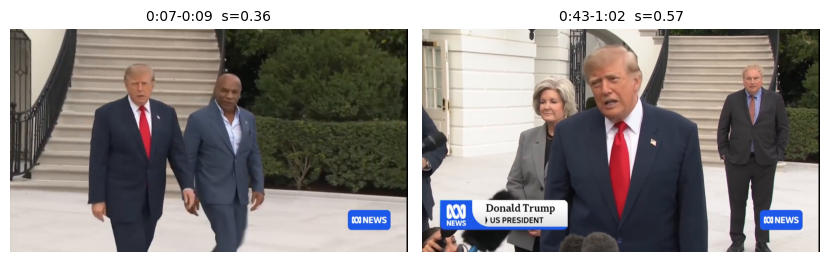


=== trump_red_tie: image=trump.jpeg text='wearing a red tie'
    {'attribute': 'a photo of a person wearing a red tie', 'lane': 'face', 'router': 'prominent face (11.7% of image, det 0.82) -> face lane', 'face_matches': 38, 'attribute_check': "color check: 'red' vs 10 other colors on the body region", 'after_attribute': 21, 'frames_matched': 21, 'stage2_ms': 1165.6}
    clip 1: 0:07-0:09 (2.0s, 2 frames, peak score 0.363)
    clip 2: 0:43-0:49 (5.5s, 6 frames, peak score 0.573)
    clip 3: 0:49-0:56 (6.5s, 7 frames, peak score 0.522)
    clip 4: 0:57-1:02 (5.5s, 6 frames, peak score 0.440)


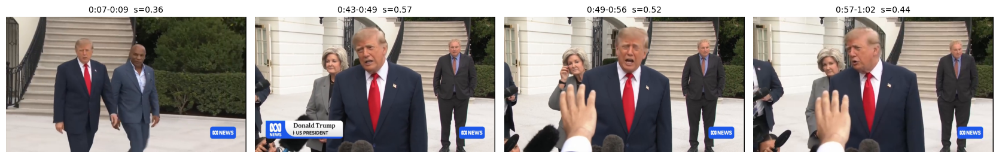


=== trump_vid_minji_control: image=minji.jpeg text=''
    {'lane': 'face', 'router': 'prominent face (24.5% of image, det 0.88) -> face lane', 'face_matches': 0, 'frames_matched': 0, 'stage2_ms': 364.7}
    no clips found
estimated face-detection time: 7.0 min
STAGE 1: 727 frames @ 4 fps | decode 20.3s | CLIP 16.1s | faces 297.2s (136 faces in 130 frames)

=== mv_minji_face: image=minji.jpeg text=''
    {'lane': 'face', 'router': 'prominent face (24.5% of image, det 0.88) -> face lane', 'face_matches': 11, 'frames_matched': 11, 'stage2_ms': 375.4}
    clip 1: 1:59-2:03 (3.5s, 10 frames, peak score 0.617)
    clip 2: 2:45-2:46 (1.2s, 1 frames, peak score 0.354)


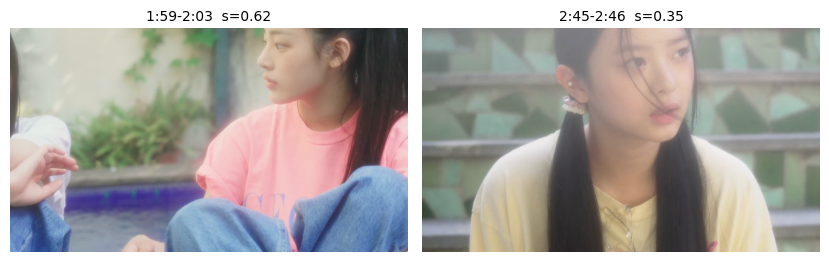


=== mv_trump_control: image=trump.jpeg text=''
    {'lane': 'face', 'router': 'prominent face (11.7% of image, det 0.82) -> face lane', 'face_matches': 0, 'frames_matched': 0, 'stage2_ms': 535.5}
    no clips found


In [6]:
# ================= RUNNER: videos x reference photos (one T4, run sequentially; each video is indexed once) =================
TRUMP_LABELS = []     # seconds where he is on screen, e.g. [(12.0, 20.5), (88.0, 95.0)]; [] = no precision/recall, thumbnails only
jobs = [
    dict(video="trump.mp4",  fps=2, runs=[("trump.jpeg", "", "trump_face", TRUMP_LABELS),
                                          ("trump.jpeg", "wearing a red tie", "trump_red_tie", TRUMP_LABELS),
                                          ("minji.jpeg", "", "trump_vid_minji_control", [])]),    # negative control: expect no clips
    dict(video="hurtMV.mp4", fps=4, runs=[("minji.jpeg", "", "mv_minji_face", []),
                                          ("trump.jpeg", "", "mv_trump_control", [])]),           # negative control: expect no clips
]
results = {}
for job in jobs:
    SAMPLE_FPS = job["fps"]                      # music videos cut fast: sample denser
    IDX = build_index(D + job["video"])
    for ref, text, tag, labels in job["runs"]:
        LABELS = labels
        results[tag] = run_query(D + ref, text, tag)